In [1]:
import pandas as pd
import numpy as np
from pyampute.exploration.mcar_statistical_tests import MCARTest
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Carregando o dataset Titanic
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

In [3]:
# Deletando 20% de Fare aleatoriamente

# Selecionando colunas numéricas para o teste
numeric_cols = ['Fare', 'SibSp', 'Parch']
df_numeric = df[numeric_cols].copy()

# Introduzir 20% de missing aleatoriamente em Fare
np.random.seed(42)  # para reprodutibilidade
mask = np.random.rand(len(df_numeric)) < 0.2
df_numeric.loc[mask, 'Fare'] = np.nan

# Realizando o Little MCAR Test
mcar_test = MCARTest(method="little")
p_value = mcar_test.little_mcar_test(df_numeric)

# Mostrando resultado e interpretação
print(f"P-valor do Little MCAR Test: {p_value:.6f}")

if p_value > 0.05:
    print("p > 0.05: Não rejeitamos a hipótese nula — os dados parecem Missing Completely at Random (MCAR).")
else:
    print("p ≤ 0.05: Rejeitamos a hipótese nula — os dados não são MCAR.")

P-valor do Little MCAR Test: 0.813908
p > 0.05: Não rejeitamos a hipótese nula — os dados parecem Missing Completely at Random (MCAR).


In [4]:
# Deletamos Fare proporcional à SibSp

# Selecionando colunas numéricas para o teste
numeric_cols = ['Fare', 'SibSp', 'Parch']
df_numeric = df[numeric_cols].copy()

# Criar missing em Fare proporcional a SibSp
np.random.seed(42)  # para reprodutibilidade

# Normalizar SibSp para usar como probabilidade de missing
sibsp_norm = df_numeric['SibSp'] / df_numeric['SibSp'].max()  # valores entre 0 e 1
prob_missing = 0.2 + 0.6 * sibsp_norm  # base 20%, aumenta com SibSp

# Gerar máscara de missing
mask = np.random.rand(len(df_numeric)) < prob_missing
df_numeric.loc[mask, 'Fare'] = np.nan

# Realizando o Little MCAR Test
mcar_test = MCARTest(method="little")
p_value = mcar_test.little_mcar_test(df_numeric)

# Mostrando resultado e interpretação
print(f"P-valor do Little MCAR Test: {p_value:.6f}")

if p_value > 0.05:
    print("p > 0.05: Não rejeitamos a hipótese nula — os dados parecem Missing Completely at Random (MCAR).")
else:
    print("p ≤ 0.05: Rejeitamos a hipótese nula — os dados não são MCAR.")

P-valor do Little MCAR Test: 0.000000
p ≤ 0.05: Rejeitamos a hipótese nula — os dados não são MCAR.


In [5]:
# Contar quantos NA existem em Age
na_count = df['Age'].isna().sum()

print(f"Existem {na_count} valores ausentes (NA) na coluna Age.")

Existem 177 valores ausentes (NA) na coluna Age.


In [6]:
# Selecionando colunas numéricas para o teste
numeric_cols = ['Age', 'Fare', 'SibSp', 'Parch']
df_numeric = df[numeric_cols]

# Realizando o Little MCAR Test
mcar_test = MCARTest(method="little")
p_value = mcar_test.little_mcar_test(df_numeric)

# Mostrando resultado e interpretação
print(f"P-valor do Little MCAR Test: {p_value:.6f}")

if p_value > 0.05:
    print("p > 0.05: Não rejeitamos a hipótese nula — os dados parecem Missing Completely at Random (MCAR).")
else:
    print("p ≤ 0.05: Rejeitamos a hipótese nula — os dados não são MCAR.")

P-valor do Little MCAR Test: 0.000015
p ≤ 0.05: Rejeitamos a hipótese nula — os dados não são MCAR.


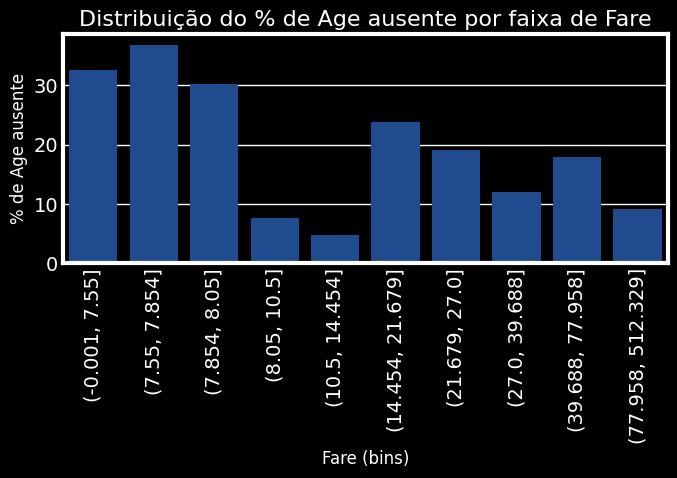

In [ ]:
# Criar uma coluna indicando se Age está ausente
df['Age_missing'] = df['Age'].isna().astype(int)

# Criar bins para Fare (por exemplo, 10 bins)
df['Fare_bin'] = pd.qcut(df['Fare'], 10, duplicates='drop')

# Calcular % de missing em Age por bin de Fare
missing_per_fare = df.groupby('Fare_bin', observed=True)['Age_missing'].mean().reset_index()
missing_per_fare['Age_missing'] *= 100  # converter para %

# Plotando
plt.style.use('dark_background')
plt.figure(figsize=(7, 5))
sns.barplot(
    x='Fare_bin',
    y='Age_missing',
    data=missing_per_fare,
    color="#0D47A1"
)
plt.xticks(rotation=90, color='white')
plt.ylabel('% de Age ausente', color='white')
plt.xlabel('Fare (bins)', color='white')
plt.title('Distribuição do % de Age ausente por faixa de Fare', color='white')

plt.tight_layout()
plt.show()